# Letter Recognition: Learning, Classification and Evaluation

**Dataset:** Letter Recognition (20,000 rows, 16 numeric features, 26 classes).  
**Libraries used:** NumPy, Pandas and Matplotlib.


## 1. Load data and EDA
Inspect shape, columns, target balance, missing values, and feature distributions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("letter-recognition.csv")

print("Shape:", data.shape)
print("Missing values:", data.isna().sum().sum())
print("Duplicate rows:", data.duplicated().sum())
print(data.head())
print(data.describe())


Shape: (20000, 17)
Missing values: 0
Duplicate rows: 1332
  letter  xbox   ybox   width   height  onpix   xbar   ybar   x2bar  y2bar   \
0      T      2      8       3       5       1      8     13      0       6   
1      I      5     12       3       7       2     10      5      5       4   
2      D      4     11       6       8       6     10      6      2       6   
3      N      7     11       6       6       3      5      9      4       6   
4      G      2      1       3       1       1      8      6      6       6   

   xybar   x2ybar  xy2bar  xedge   xedgey  yedge   yedgex  
0       6      10       8       0       8       0       8  
1      13       3       9       2       8       4      10  
2      10       3       7       3       7       3       9  
3       4       4      10       6      10       2       8  
4       6       5       9       1       7       5      10  
              xbox          ybox         width        height        onpix   \
count  20000.000000  20000.00

Number of classes: 26
letter
A    789
B    766
C    736
D    805
E    768
F    775
G    773
H    734
I    755
J    747
K    739
L    761
M    792
N    783
O    753
P    803
Q    783
R    758
S    748
T    796
U    813
V    764
W    752
X    787
Y    786
Z    734
Name: count, dtype: int64


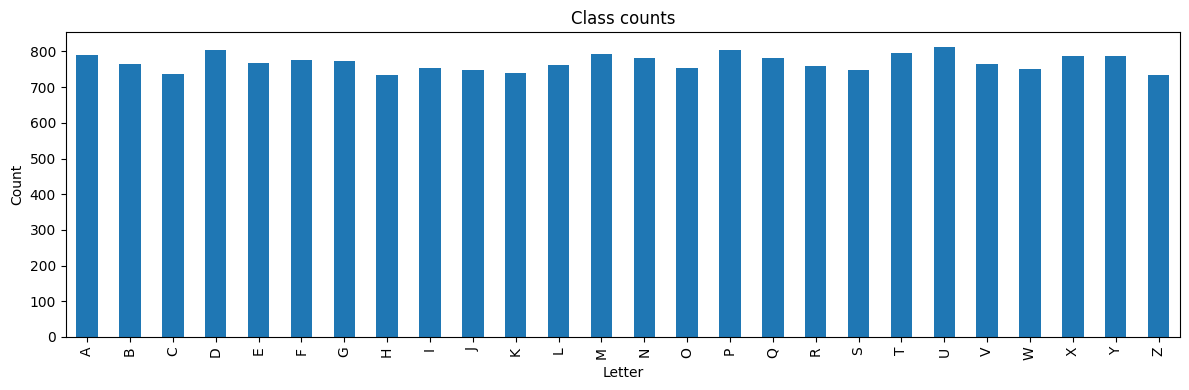

In [2]:
target_column = "letter"
feature_columns = [column for column in data.columns if column != target_column]

print("Number of classes:", data[target_column].nunique())
print(data[target_column].value_counts().sort_index())

data[target_column].value_counts().sort_index().plot(kind="bar", figsize=(12, 4))
plt.title("Class counts")
plt.xlabel("Letter")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


### Feature Description

The dataset contains 16 numerical features describing the shape and pixel distribution of handwritten letters.

- **xbox:** Horizontal position of the letter's bounding box.
- **ybox:** Vertical position of the letter's bounding box.
- **width:** Width of the letter's bounding box.
- **height:** Height of the letter's bounding box.
- **onpix:** Total number of pixels forming the letter.
- **xbar:** Average horizontal position of the pixels.
- **ybar:** Average vertical position of the pixels.
- **x2bar:** Horizontal distribution of pixels.
- **y2bar:** Vertical distribution of pixels.
- **xybar:** Average diagonal distribution of pixels.
- **x2ybar:** Horizontal distribution weighted by vertical position.
- **xy2bar:** Vertical distribution weighted by horizontal position.
- **xedge:** Number of horizontal edges in the letter.
- **xedgey:** Horizontal edges weighted by vertical position.
- **yedge:** Number of vertical edges in the letter.
- **yedgex:** Vertical edges weighted by horizontal position.

**Target (`letter`):** The actual handwritten letter, belonging to one of the 26 classes (A–Z).

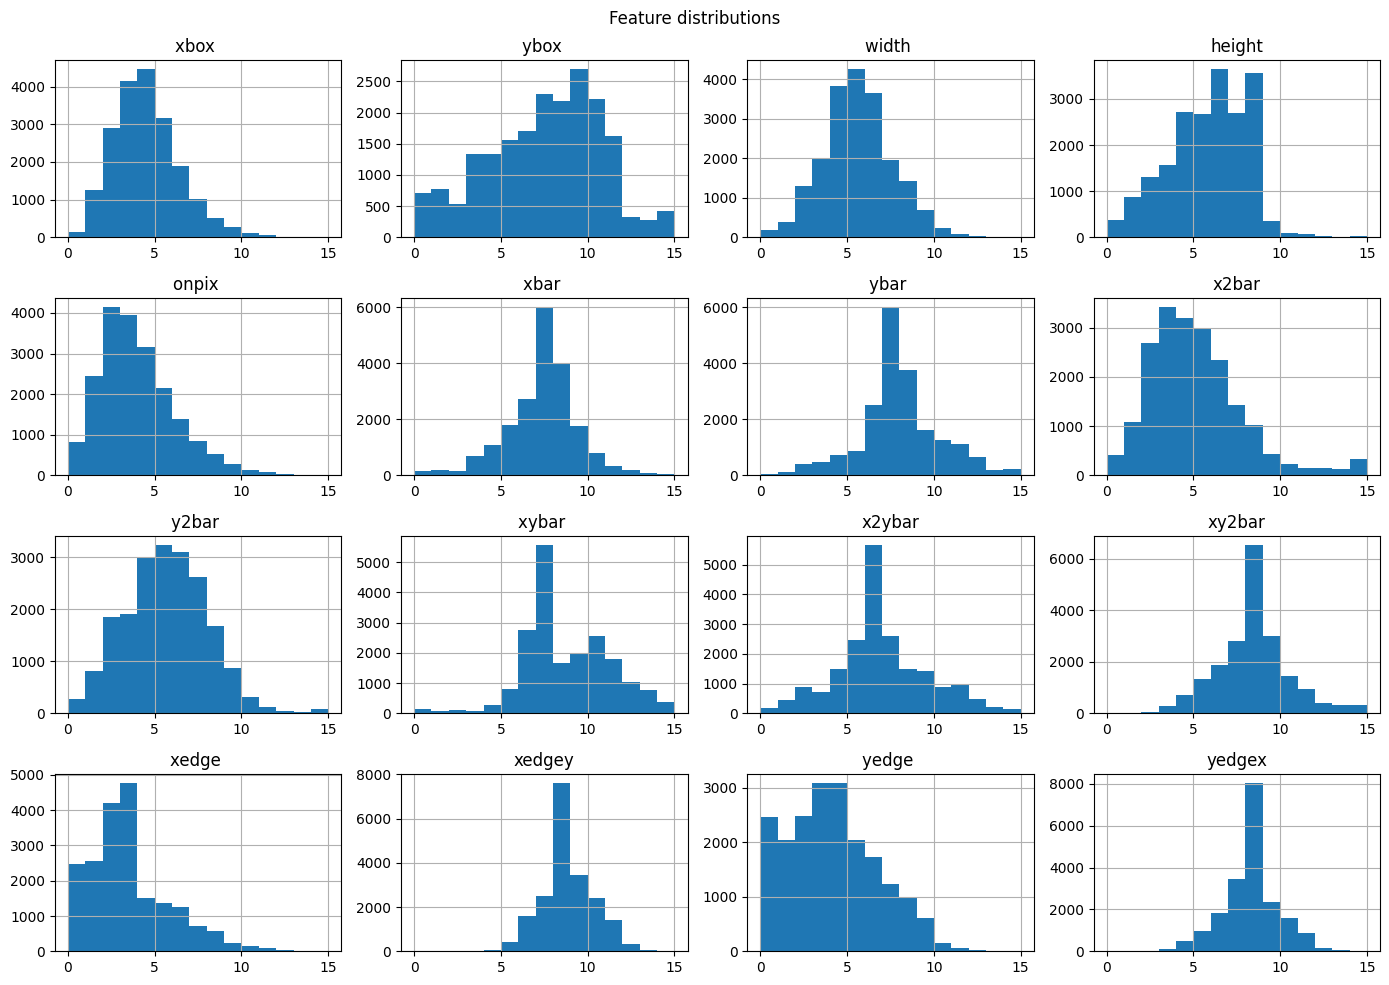

In [3]:
data[feature_columns].hist(figsize=(14, 10), bins=15)
plt.suptitle("Feature distributions")
plt.tight_layout()
plt.show()


## 2. Preprocessing

- **Missing values:** replace numeric missing values with the column median.
- **Outliers:** cap values to the IQR fences (Q1 − 1.5×IQR, Q3 + 1.5×IQR).
- **Scaling:** standardize features using training data statistics.
- **Normalisation:** min-max scale features to [0, 1].

The letter dataset has no missing values.


Number of classes: 26
letter
A    789
B    766
C    736
D    805
E    768
F    775
G    773
H    734
I    755
J    747
K    739
L    761
M    792
N    783
O    753
P    803
Q    783
R    758
S    748
T    796
U    813
V    764
W    752
X    787
Y    786
Z    734
Name: count, dtype: int64


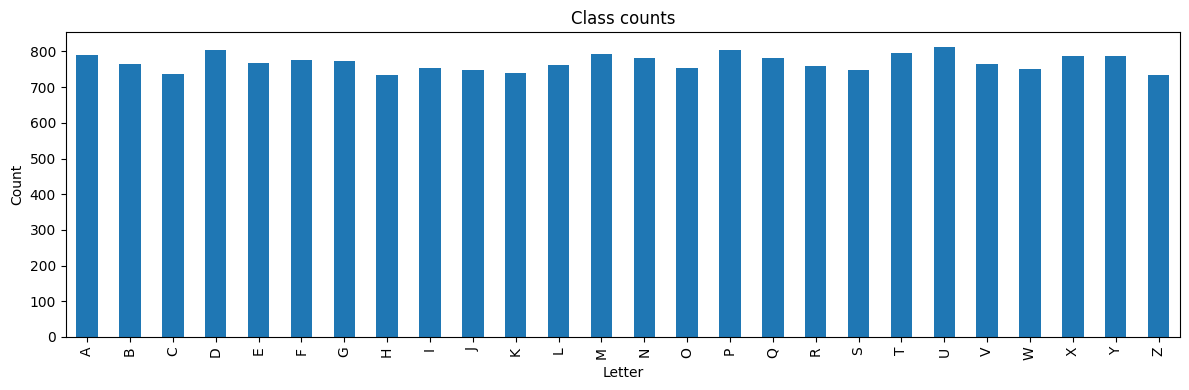

In [4]:
target_column = "letter"
feature_columns = [column for column in data.columns if column != target_column]

print("Number of classes:", data[target_column].nunique())
print(data[target_column].value_counts().sort_index())

data[target_column].value_counts().sort_index().plot(kind="bar", figsize=(12, 4))
plt.title("Class counts")
plt.xlabel("Letter")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


In [5]:
features = data[feature_columns].copy()

# Fill missing values with each feature's median. Since no missing values are present, this operation does not modify the dataset.
features = features.fillna(features.median())

# IQR-based capping
q1 = features.quantile(0.25)
q3 = features.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
features = features.clip(lower=lower_fence, upper=upper_fence, axis=1)

# Standard scaling
feature_mean = features.mean()
feature_std = features.std().replace(0, 1)
standard_features = (features - feature_mean) / feature_std

# Min-max normalisation
feature_min = features.min()
feature_range = (features.max() - feature_min).replace(0, 1)
normalised_features = (features - feature_min) / feature_range

print("Preprocessed feature shape:", standard_features.shape)
print("Standardised means (approx. 0):")
print(standard_features.mean().round(2).head())
print("Normalised range:", normalised_features.min().min(), "to", normalised_features.max().max())


Preprocessed feature shape: (20000, 16)
Standardised means (approx. 0):
xbox      0.0
ybox      0.0
width    -0.0
height   -0.0
onpix    -0.0
dtype: float64
Normalised range: 0.0 to 1.0


## 3. K-Means clustering and Elbow method

K-Means assigns each point to its nearest centroid, then updates centroids as cluster means. The elbow method compares within-cluster sum of squared distances (WCSS) for different values of *k*. The curve's bend is a useful heuristic, not a guaranteed optimum.

For runtime, the elbow calculation uses a reproducible subset and a NumPy implementation.


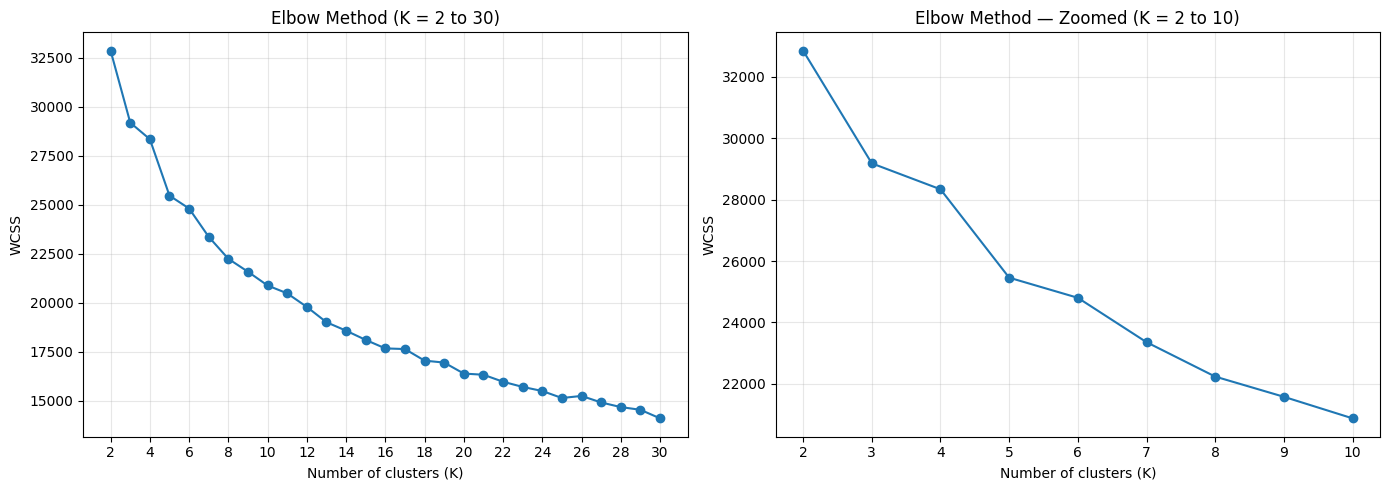

In [11]:
# Calculate WCSS for K = 2 to 30
k_values = range(2, 31)
wcss_values = []

for k in k_values:
    labels, centroids, wcss = kmeans(cluster_sample, k)
    wcss_values.append(wcss)

# Plot both ranges
plt.figure(figsize=(14, 5))

# Full range: K = 2 to 30
plt.subplot(1, 2, 1)
plt.plot(list(k_values), wcss_values, marker="o")
plt.title("Elbow Method (K = 2 to 30)")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(2, 31, 2))
plt.grid(True, alpha=0.3)

# Zoomed range: K = 2 to 10
plt.subplot(1, 2, 2)
plt.plot(list(k_values)[:9], wcss_values[:9], marker="o")
plt.title("Elbow Method — Zoomed (K = 2 to 10)")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. DBSCAN

DBSCAN groups points with enough nearby neighbours and labels sparse points as noise. It uses two parameters: `eps` (neighbourhood radius) and `min_points` (minimum neighbours).

The straightforward implementation below is quadratic in the number of points, so it runs on a small sample.


In [12]:
def dbscan(points, eps, min_points):
    number_of_points = len(points)
    labels = np.full(number_of_points, -1)  # -1 means noise
    visited = np.zeros(number_of_points, dtype=bool)
    cluster_id = 0

    # Precompute neighbourhoods
    neighbourhoods = []
    for i in range(number_of_points):
        distances = np.sqrt(((points - points[i]) ** 2).sum(axis=1))
        neighbourhoods.append(np.where(distances <= eps)[0])

    for point in range(number_of_points):
        if visited[point]:
            continue
        visited[point] = True
        neighbours = neighbourhoods[point]

        if len(neighbours) < min_points:
            continue

        labels[point] = cluster_id
        queue = list(neighbours)
        position = 0

        while position < len(queue):
            neighbour = queue[position]
            position += 1

            if not visited[neighbour]:
                visited[neighbour] = True
                nearby = neighbourhoods[neighbour]
                if len(nearby) >= min_points:
                    for candidate in nearby:
                        if candidate not in queue:
                            queue.append(candidate)

            if labels[neighbour] == -1:
                labels[neighbour] = cluster_id

        cluster_id += 1

    return labels


dbscan_sample = standard_features.sample(n=1000, random_state=1).to_numpy()
dbscan_labels = dbscan(dbscan_sample, eps=2.5, min_points=8)

cluster_ids, cluster_counts = np.unique(dbscan_labels, return_counts=True)
print("Clusters found (excluding noise):", len(cluster_ids[cluster_ids != -1]))
print("Noise points:", (dbscan_labels == -1).sum())
print("Cluster labels and counts:", dict(zip(cluster_ids, cluster_counts)))


Clusters found (excluding noise): 4
Noise points: 184
Cluster labels and counts: {np.int64(-1): np.int64(184), np.int64(0): np.int64(745), np.int64(1): np.int64(57), np.int64(2): np.int64(6), np.int64(3): np.int64(8)}


## 5. Principal Component Analysis (PCA)

PCA projects data onto directions of greatest variance. We centre the features, compute the covariance matrix, and use eigenvectors as principal directions. The plot shows the first two components.


Variance explained by first two components: 0.4404


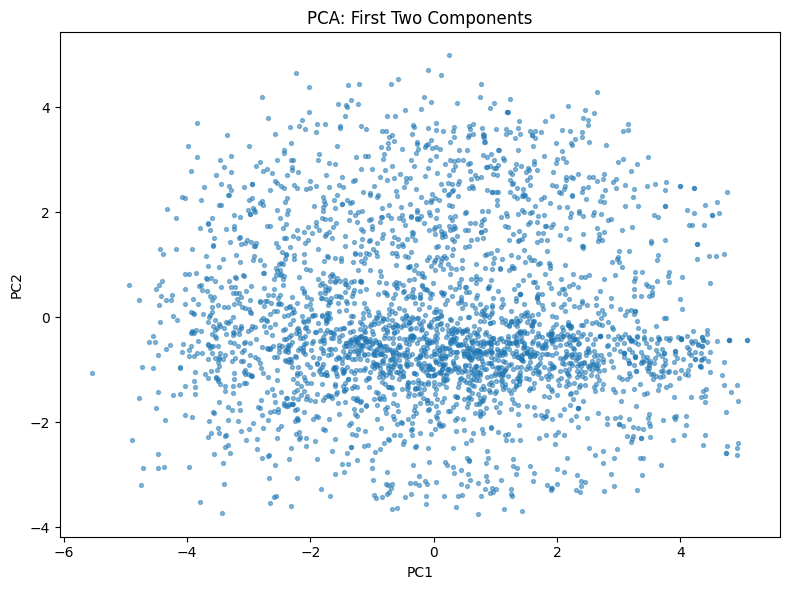

In [8]:
pca_points = standard_features.to_numpy()
centred_points = pca_points - pca_points.mean(axis=0)
covariance = np.cov(centred_points, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(covariance)

# Sort components in descending order of eigenvalues
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

# Feature reduction: 16 original features -> 2 principal components
two_components = eigenvectors[:, :2]

pca_result = centred_points @ two_components    # Project the data

explained_variance = eigenvalues / eigenvalues.sum()
print("Variance explained by first two components:",
      explained_variance[:2].sum().round(4))

plt.figure(figsize=(8, 6))
plt.scatter(pca_result[:3000, 0], pca_result[:3000, 1],
            s=8, alpha=0.5)

plt.title("PCA: First Two Components")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()


## 6. Compare classifiers using Stratified 5-Fold Cross-Validation

Compare KNN, Logistic Regression, linear SVM and Gaussian Naïve Bayes. Each fold keeps class proportions similar. Scaling is fitted on each training fold only to prevent data leakage. A balanced subset (up to 100 samples per letter) keeps runtime manageable.

KNN (k=5)
Fold accuracies: [0.8154 0.825  0.8462 0.8115 0.7673]
Mean accuracy: 0.8131
Standard deviation: 0.0258

Logistic Regression
Fold accuracies: [0.5981 0.6115 0.6212 0.5865 0.6077]
Mean accuracy: 0.605
Standard deviation: 0.0118

Linear SVM (OvR)
Fold accuracies: [0.4308 0.4327 0.4635 0.4231 0.4231]
Mean accuracy: 0.4346
Standard deviation: 0.0149

Gaussian Naive Bayes
Fold accuracies: [0.6231 0.5904 0.675  0.6385 0.6058]
Mean accuracy: 0.6265
Standard deviation: 0.0291

Best model: KNN (k=5)
Best mean accuracy: 0.8131


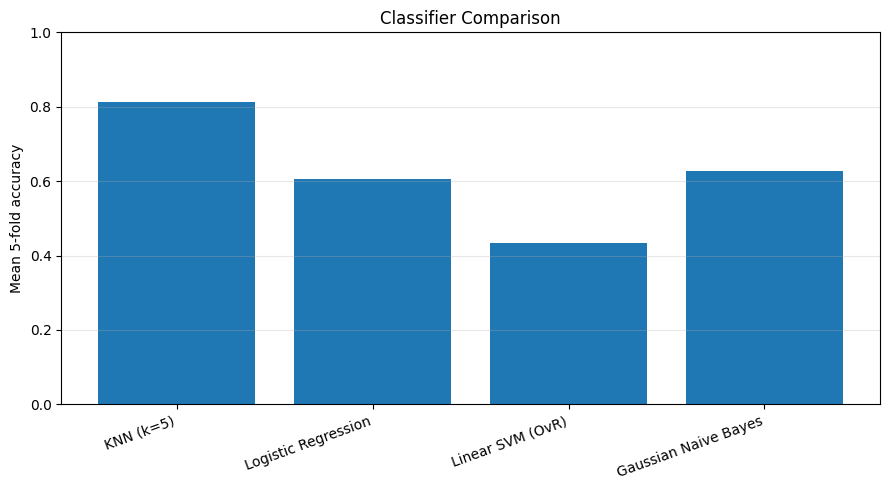

In [13]:
# Balanced subset: at most 100 samples for each letter
evaluation_data = data.groupby(target_column, group_keys=False).head(100)

evaluation_x = evaluation_data[feature_columns].to_numpy(dtype=float)
evaluation_y = evaluation_data[target_column].to_numpy()

# Create stratified 5-folds
folds = stratified_folds(evaluation_y, number_of_folds=5, seed=0)

# Models to compare
models = {
    "KNN (k=5)": knn_predict,
    "Logistic Regression": logistic_predict,
    "Linear SVM (OvR)": svm_predict,
    "Gaussian Naive Bayes": naive_bayes_predict
}

results = {}

# Evaluate each model using the same folds
for model_name, predict_function in models.items():
    accuracies = []

    for fold_number in range(5):
        test_indices = folds[fold_number]
        train_indices = np.concatenate(
            [folds[i] for i in range(5) if i != fold_number]
        )

        train_x = evaluation_x[train_indices].copy()
        test_x = evaluation_x[test_indices].copy()
        train_y = evaluation_y[train_indices]
        test_y = evaluation_y[test_indices]

        # Fit standard scaling using training data only
        mean = train_x.mean(axis=0)
        std = train_x.std(axis=0)
        std[std == 0] = 1

        train_x = (train_x - mean) / std
        test_x = (test_x - mean) / std

        # Predict and calculate accuracy
        predictions = predict_function(train_x, train_y, test_x)
        accuracy = (predictions == test_y).mean()
        accuracies.append(accuracy)

    results[model_name] = accuracies

    print(model_name)
    print("Fold accuracies:", np.round(accuracies, 4))
    print("Mean accuracy:", round(np.mean(accuracies), 4))
    print("Standard deviation:", round(np.std(accuracies), 4))
    print()

# Find the model with the highest mean accuracy
mean_accuracies = {
    name: np.mean(scores)
    for name, scores in results.items()
}

best_model = max(mean_accuracies, key=mean_accuracies.get)

print("Best model:", best_model)
print("Best mean accuracy:", round(mean_accuracies[best_model], 4))

# Plot model comparison
plt.figure(figsize=(9, 5))

model_names = list(mean_accuracies.keys())
model_scores = list(mean_accuracies.values())

plt.bar(model_names, model_scores)
plt.ylabel("Mean 5-fold accuracy")
plt.title("Classifier Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Summary

- EDA checked dataset size, class balance, missing values and feature distributions.
- Preprocessing demonstrated median imputation, IQR capping, standard scaling and min-max normalisation.
- K-Means used an elbow curve; DBSCAN explored dense groups and noise.
- PCA reduced 16 features to 2 components for visualisation.
- KNN, Logistic Regression, linear SVM and Gaussian Naïve Bayes were compared using stratified 5-fold cross-validation.
- The best model is selected by the highest mean fold accuracy; results depend on the chosen subset and model settings.
